# Stage 3 – Lung Segmentation

## Objective

The objective of this notebook is to segment the lung regions from chest X-ray images before disease classification.

This stage performs:

1. Loading chest X-ray images
2. Loading corresponding lung masks
3. Visualizing image-mask pairs
4. Dataset verification
5. Preparing data for segmentation model
6. Training SegFusionFormer
7. Saving the trained model
8. Generating segmented lung images

Author: Solomon Rajan P
Project: SegFusionFormer

In [1]:
# ============================================================
# Lung Segmentation using U-Net
# Project : SegFusionFormer
# Author  : Solomon Rajan P
# ============================================================

import os
import random
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from tqdm.auto import tqdm

print("=" * 60)
print("Lung Segmentation using U-Net")
print("=" * 60)

print(f"PyTorch Version : {torch.__version__}")
print(f"OpenCV Version  : {cv2.__version__}")

Lung Segmentation using U-Net
PyTorch Version : 2.10.0
OpenCV Version  : 4.13.0


In [2]:
# ============================================================
# Step 2 : Detect Computing Device
# ============================================================

if torch.backends.mps.is_available():
    device = torch.device("mps")
    device_name = "Apple Silicon GPU (MPS)"
elif torch.cuda.is_available():
    device = torch.device("cuda")
    device_name = torch.cuda.get_device_name(0)
else:
    device = torch.device("cpu")
    device_name = "CPU"

print("=" * 60)
print("Device Configuration")
print("=" * 60)

print(f"Device      : {device}")
print(f"Description : {device_name}")

Device Configuration
Device      : mps
Description : Apple Silicon GPU (MPS)


In [3]:
# ============================================================
# Step 3 : Define Project Paths
# ============================================================

project_root = Path.cwd().parent

dataset_path = project_root / "segmentation_dataset"
images_dir = dataset_path / "images"
masks_dir = dataset_path / "masks"

models_dir = project_root / "models"
outputs_dir = project_root / "outputs"

# Create folders if they don't exist
models_dir.mkdir(exist_ok=True)
outputs_dir.mkdir(exist_ok=True)

print("=" * 60)
print("Project Paths")
print("=" * 60)

print(f"Project Root : {project_root}")
print(f"Dataset      : {dataset_path}")
print(f"Images       : {images_dir}")
print(f"Masks        : {masks_dir}")
print(f"Models       : {models_dir}")
print(f"Outputs      : {outputs_dir}")

print("\nFolder Status")
print("-" * 60)
print(f"Images Exists : {images_dir.exists()}")
print(f"Masks Exists  : {masks_dir.exists()}")
print(f"Models Exists : {models_dir.exists()}")
print(f"Outputs Exists: {outputs_dir.exists()}")

Project Paths
Project Root : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer
Dataset      : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/segmentation_dataset
Images       : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/segmentation_dataset/images
Masks        : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/segmentation_dataset/masks
Models       : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/models
Outputs      : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/outputs

Folder Status
------------------------------------------------------------
Images Exists : True
Masks Exists  : True
Models Exists : True
Outputs Exists: True


In [4]:
# ============================================================
# Step 4 : Verify Dataset
# ============================================================

# Get all image files
image_files = sorted(images_dir.glob("*.png"))
mask_files = sorted(masks_dir.glob("*.png"))

print("=" * 60)
print("Dataset Verification")
print("=" * 60)

print(f"Total Images : {len(image_files)}")
print(f"Total Masks  : {len(mask_files)}")

valid_images = []
valid_masks = []

missing_masks = 0

for img_path in image_files:

    img_name = img_path.stem
    mask_path = masks_dir / f"{img_name}_mask.png"

    if mask_path.exists():
        valid_images.append(img_path)
        valid_masks.append(mask_path)
    else:
        missing_masks += 1

print("\nValid Image-Mask Pairs :", len(valid_images))
print("Missing Masks          :", missing_masks)

print("\nFirst 5 Valid Pairs")
print("-" * 60)

for i in range(min(5, len(valid_images))):
    print(valid_images[i].name, "<---->", valid_masks[i].name)

Dataset Verification
Total Images : 800
Total Masks  : 704

Valid Image-Mask Pairs : 566
Missing Masks          : 234

First 5 Valid Pairs
------------------------------------------------------------
CHNCXR_0001_0.png <----> CHNCXR_0001_0_mask.png
CHNCXR_0002_0.png <----> CHNCXR_0002_0_mask.png
CHNCXR_0003_0.png <----> CHNCXR_0003_0_mask.png
CHNCXR_0004_0.png <----> CHNCXR_0004_0_mask.png
CHNCXR_0005_0.png <----> CHNCXR_0005_0_mask.png


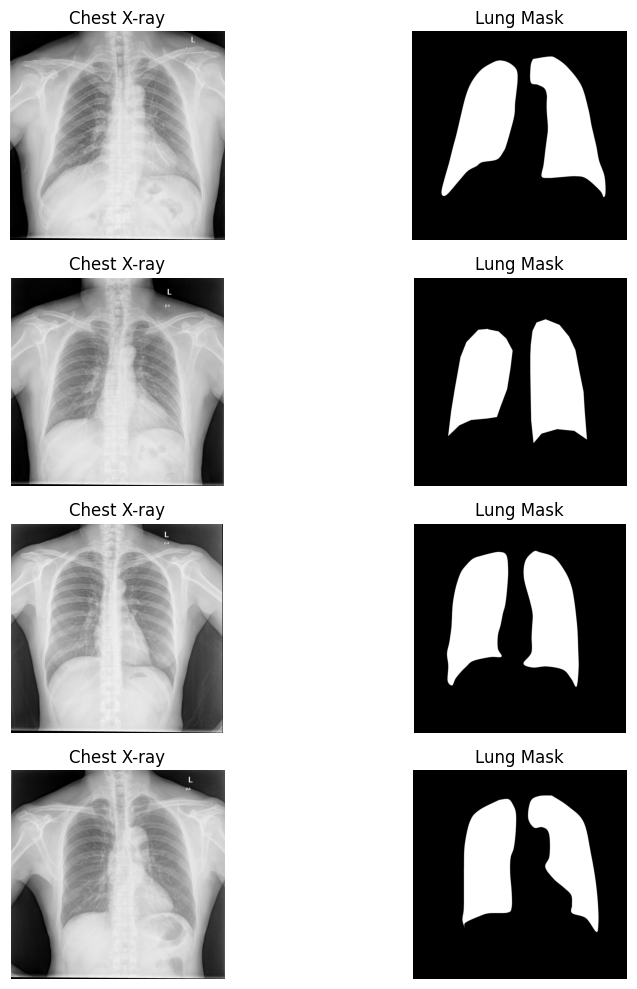

In [5]:
# ============================================================
# Step 5 : Visualize Sample Image-Mask Pairs
# ============================================================

num_samples = 4

plt.figure(figsize=(10, 10))

for i in range(num_samples):

    # Read image (grayscale)
    image = cv2.imread(str(valid_images[i]), cv2.IMREAD_GRAYSCALE)

    # Read mask (grayscale)
    mask = cv2.imread(str(valid_masks[i]), cv2.IMREAD_GRAYSCALE)

    # Original Image
    plt.subplot(num_samples, 2, 2*i + 1)
    plt.imshow(image, cmap="gray")
    plt.title("Chest X-ray")
    plt.axis("off")

    # Corresponding Mask
    plt.subplot(num_samples, 2, 2*i + 2)
    plt.imshow(mask, cmap="gray")
    plt.title("Lung Mask")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
# ==========================================================
# Step 6.1 : Import Libraries
# ==========================================================

import cv2
import numpy as np
import torch

In [7]:
IMG_SIZE = 256

def preprocess(image_path, mask_path):

    # Read image
    image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

    # Read mask
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

    # Resize image
    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))

    # Resize mask (Nearest Neighbor)
    mask = cv2.resize(
        mask,
        (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_NEAREST
    )

    # Normalize image
    image = image.astype(np.float32) / 255.0

    # Binary mask
    mask = (mask > 0).astype(np.float32)

    # Convert to tensors
    image = torch.tensor(image).unsqueeze(0)
    mask = torch.tensor(mask).unsqueeze(0)

    return image, mask

In [8]:
# ==========================================================
# Step 6.3 : Test Preprocessing
# ==========================================================

image, mask = preprocess(valid_images[0], valid_masks[0])

print("=" * 60)
print("Preprocessing Test")
print("=" * 60)

print("Image Shape :", image.shape)
print("Mask Shape  :", mask.shape)

print("\nImage Range")
print(image.min().item(), "to", image.max().item())

print("\nMask Values")
print(torch.unique(mask))

Preprocessing Test
Image Shape : torch.Size([1, 256, 256])
Mask Shape  : torch.Size([1, 256, 256])

Image Range
0.0 to 1.0

Mask Values
tensor([0., 1.])


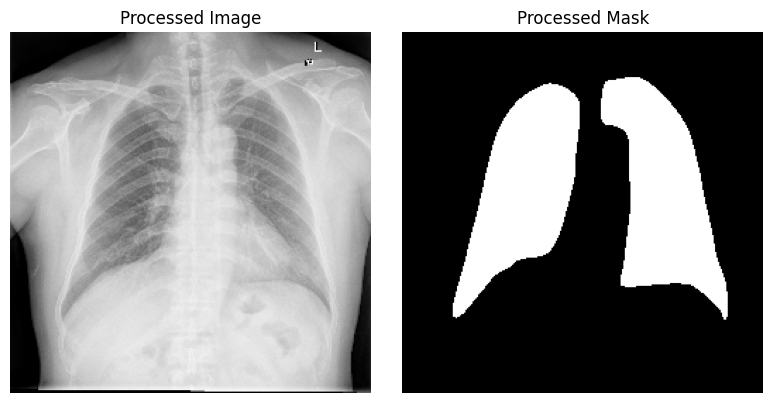

In [9]:
# ==========================================================
# Step 6.4 : Visualize After Preprocessing
# ==========================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))

plt.subplot(1,2,1)
plt.imshow(image.squeeze(), cmap="gray")
plt.title("Processed Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(mask.squeeze(), cmap="gray")
plt.title("Processed Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
# ==========================================================
# Step 7 : Create LungDataset Class
# ==========================================================

from torch.utils.data import Dataset

class LungDataset(Dataset):

    def __init__(self, image_paths, mask_paths):
        self.image_paths = image_paths
        self.mask_paths = mask_paths

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):

        image, mask = preprocess(
            self.image_paths[idx],
            self.mask_paths[idx]
        )

        return image, mask

In [11]:
# ==========================================================
# Step 7.1 : Test LungDataset
# ==========================================================

dataset = LungDataset(valid_images, valid_masks)

print("=" * 60)
print("Dataset Test")
print("=" * 60)

print("Dataset Size :", len(dataset))

image, mask = dataset[0]

print("\nImage Shape :", image.shape)
print("Mask Shape  :", mask.shape)

print("\nImage Range")
print(image.min().item(), "to", image.max().item())

print("\nMask Values")
print(torch.unique(mask))

Dataset Test
Dataset Size : 566

Image Shape : torch.Size([1, 256, 256])
Mask Shape  : torch.Size([1, 256, 256])

Image Range
0.0 to 1.0

Mask Values
tensor([0., 1.])


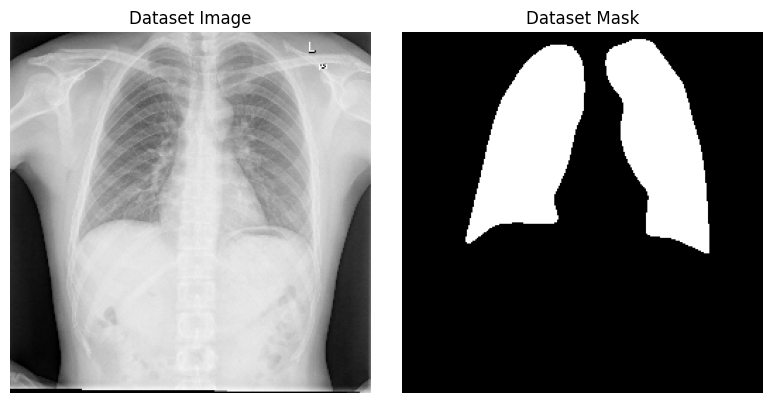

In [12]:
# ==========================================================
# Step 7.2 : Visualize Dataset Sample
# ==========================================================

import matplotlib.pyplot as plt

image, mask = dataset[10]

plt.figure(figsize=(8,4))

plt.subplot(1,2,1)
plt.imshow(image.squeeze(), cmap="gray")
plt.title("Dataset Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(mask.squeeze(), cmap="gray")
plt.title("Dataset Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [13]:
# ==========================================================
# Step 8.1 : Import DataLoader
# ==========================================================

from torch.utils.data import DataLoader

In [14]:
# ==========================================================
# Step 8.2 : Create DataLoader
# ==========================================================

BATCH_SIZE = 4

train_loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

print("=" * 60)
print("DataLoader Created")
print("=" * 60)

print("Batch Size :", BATCH_SIZE)
print("Number of Batches :", len(train_loader))

DataLoader Created
Batch Size : 4
Number of Batches : 142


In [15]:
# ==========================================================
# Step 8.3 : Test DataLoader
# ==========================================================

images, masks = next(iter(train_loader))

print("=" * 60)
print("First Batch")
print("=" * 60)

print("Images Shape :", images.shape)
print("Masks Shape  :", masks.shape)

print("\nImage Range")
print(images.min().item(), "to", images.max().item())

print("\nMask Values")
print(torch.unique(masks))

First Batch
Images Shape : torch.Size([4, 1, 256, 256])
Masks Shape  : torch.Size([4, 1, 256, 256])

Image Range
0.0 to 1.0

Mask Values
tensor([0., 1.])


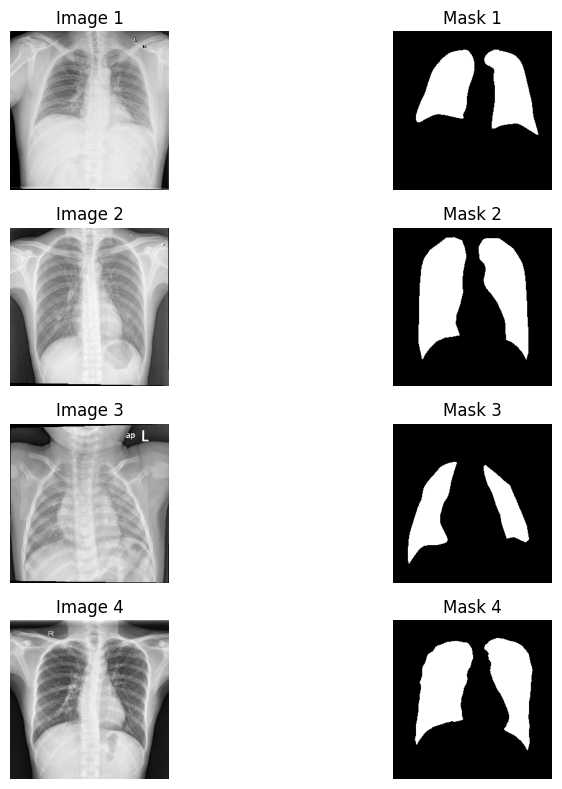

In [16]:
# ==========================================================
# Step 8.4 : Visualize Batch
# ==========================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))

for i in range(4):

    plt.subplot(4,2,2*i+1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(f"Image {i+1}")
    plt.axis("off")

    plt.subplot(4,2,2*i+2)
    plt.imshow(masks[i].squeeze(), cmap="gray")
    plt.title(f"Mask {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [17]:
# ==========================================================
# Step 9 : Double Convolution Block
# ==========================================================

import torch.nn as nn

class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(out_channels),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(out_channels),

            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

In [18]:
# ==========================================================
# Step 9.1 : Test DoubleConv
# ==========================================================

# Create DoubleConv block
double_conv = DoubleConv(1, 64)

# Move to device
double_conv = double_conv.to(device)

# Create a dummy input
x = torch.randn(4, 1, 256, 256).to(device)

# Forward pass
with torch.no_grad():
    y = double_conv(x)

print("=" * 60)
print("DoubleConv Test")
print("=" * 60)

print(f"Input Shape  : {x.shape}")
print(f"Output Shape : {y.shape}")

DoubleConv Test
Input Shape  : torch.Size([4, 1, 256, 256])
Output Shape : torch.Size([4, 64, 256, 256])


In [19]:
# ==========================================================
# Step 10 : Down Block (Encoder)
# ==========================================================

class Down(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.MaxPool2d(kernel_size=2, stride=2),
            DoubleConv(in_channels, out_channels)
        )

    def forward(self, x):
        return self.block(x)

In [20]:
# ==========================================================
# Step 10.1 : Test Down Block
# ==========================================================

# Create Down block and move to device
down = Down(64, 128).to(device)

# Get one batch from DataLoader
images, masks = next(iter(train_loader))

# Move images to GPU (MPS)
images = images.to(device)

# Create DoubleConv block and move to device
double_conv = DoubleConv(1, 64).to(device)

# Extract encoder features
features = double_conv(images)

# Pass through Down block
down_output = down(features)

print("=" * 60)
print("Down Block Test")
print("=" * 60)

print("Input Shape  :", features.shape)
print("Output Shape :", down_output.shape)

# Verify device
print("\nDevice Check")
print("Images Device      :", images.device)
print("Features Device    :", features.device)
print("Down Output Device :", down_output.device)

Down Block Test
Input Shape  : torch.Size([4, 64, 256, 256])
Output Shape : torch.Size([4, 128, 128, 128])

Device Check
Images Device      : mps:0
Features Device    : mps:0
Down Output Device : mps:0


In [21]:
# ==========================================================
# Step 11 : Up Block (Decoder)
# ==========================================================

class Up(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        # Upsampling using Transposed Convolution
        self.up = nn.ConvTranspose2d(
            in_channels,
            in_channels // 2,
            kernel_size=2,
            stride=2
        )

        # Double convolution after concatenation
        self.conv = DoubleConv(in_channels, out_channels)

    def forward(self, x1, x2):
        """
        x1 : Decoder feature map
        x2 : Skip connection from encoder
        """

        # Upsample decoder feature map
        x1 = self.up(x1)

        # If dimensions differ by 1 pixel, resize safely
        if x1.shape[2:] != x2.shape[2:]:
            x1 = nn.functional.interpolate(
                x1,
                size=x2.shape[2:],
                mode="bilinear",
                align_corners=False
            )

        # Concatenate along channel dimension
        x = torch.cat([x2, x1], dim=1)

        # Apply DoubleConv
        x = self.conv(x)

        return x

In [22]:
# ==========================================================
# Step 11.1 : Test Up Block
# ==========================================================

# Create Up block and move it to MPS
up = Up(128, 64).to(device)

# Get one batch
images, masks = next(iter(train_loader))
images = images.to(device)

# Encoder feature at full resolution
encoder_block = DoubleConv(1, 64).to(device)
skip_feature = encoder_block(images)

# Downsample feature
down_block = Down(64, 128).to(device)
decoder_input = down_block(skip_feature)

# Pass through Up block
up_output = up(decoder_input, skip_feature)

print("=" * 60)
print("Up Block Test")
print("=" * 60)

print("Decoder Input :", decoder_input.shape)
print("Skip Feature  :", skip_feature.shape)
print("Output Shape  :", up_output.shape)

print("\nDevice Check")
print("Decoder Device :", decoder_input.device)
print("Skip Device    :", skip_feature.device)
print("Output Device  :", up_output.device)

Up Block Test
Decoder Input : torch.Size([4, 128, 128, 128])
Skip Feature  : torch.Size([4, 64, 256, 256])
Output Shape  : torch.Size([4, 64, 256, 256])

Device Check
Decoder Device : mps:0
Skip Device    : mps:0
Output Device  : mps:0


In [23]:
# ==========================================================
# Step 12 : Complete Memory-Efficient U-Net
# ==========================================================

class UNet(nn.Module):

    def __init__(self, in_channels=1, out_channels=1):
        super().__init__()

        # --------------------------------------------------
        # Encoder
        # --------------------------------------------------

        self.inc = DoubleConv(in_channels, 32)

        self.down1 = Down(32, 64)
        self.down2 = Down(64, 128)
        self.down3 = Down(128, 256)

        # Bottleneck
        self.down4 = Down(256, 512)

        # --------------------------------------------------
        # Decoder
        # --------------------------------------------------

        self.up1 = Up(512, 256)
        self.up2 = Up(256, 128)
        self.up3 = Up(128, 64)
        self.up4 = Up(64, 32)

        # Final 1x1 convolution
        self.outc = nn.Conv2d(
            32,
            out_channels,
            kernel_size=1
        )

    def forward(self, x):

        # Encoder
        x1 = self.inc(x)        # 32 x 256 x 256
        x2 = self.down1(x1)     # 64 x 128 x 128
        x3 = self.down2(x2)     # 128 x 64 x 64
        x4 = self.down3(x3)     # 256 x 32 x 32
        x5 = self.down4(x4)     # 512 x 16 x 16

        # Decoder + Skip Connections
        x = self.up1(x5, x4)    # 256 x 32 x 32
        x = self.up2(x, x3)     # 128 x 64 x 64
        x = self.up3(x, x2)     # 64 x 128 x 128
        x = self.up4(x, x1)     # 32 x 256 x 256

        # Final segmentation logits
        logits = self.outc(x)

        return logits

In [24]:
# ==========================================================
# Step 12.1 : Instantiate U-Net and Test Forward Pass
# ==========================================================

# Create model
model = UNet(
    in_channels=1,
    out_channels=1
).to(device)

# Get one batch from DataLoader
images, masks = next(iter(train_loader))

# Move batch to MPS
images = images.to(device)
masks = masks.to(device)

# Test forward pass without gradients
model.eval()

with torch.no_grad():
    outputs = model(images)

print("=" * 60)
print("Complete U-Net Forward Pass Test")
print("=" * 60)

print("Input Shape        :", images.shape)
print("Ground Truth Shape :", masks.shape)
print("Output Shape       :", outputs.shape)

print("\nDevice Check")
print("Model Device  :", next(model.parameters()).device)
print("Images Device :", images.device)
print("Output Device :", outputs.device)

Complete U-Net Forward Pass Test
Input Shape        : torch.Size([4, 1, 256, 256])
Ground Truth Shape : torch.Size([4, 1, 256, 256])
Output Shape       : torch.Size([4, 1, 256, 256])

Device Check
Model Device  : mps:0
Images Device : mps:0
Output Device : mps:0


In [25]:
# ==========================================================
# Step 13 : BCE + Dice Loss
# ==========================================================

class DiceLoss(nn.Module):

    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):

        # Convert logits to probabilities
        probs = torch.sigmoid(logits)

        # Flatten each sample
        probs = probs.view(probs.size(0), -1)
        targets = targets.view(targets.size(0), -1)

        # Intersection
        intersection = (probs * targets).sum(dim=1)

        # Dice score
        dice = (
            2.0 * intersection + self.smooth
        ) / (
            probs.sum(dim=1)
            + targets.sum(dim=1)
            + self.smooth
        )

        # Dice loss
        return 1.0 - dice.mean()


class BCEDiceLoss(nn.Module):

    def __init__(self, bce_weight=0.5, dice_weight=0.5):
        super().__init__()

        self.bce = nn.BCEWithLogitsLoss()
        self.dice = DiceLoss()

        self.bce_weight = bce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):

        bce_loss = self.bce(logits, targets)
        dice_loss = self.dice(logits, targets)

        total_loss = (
            self.bce_weight * bce_loss
            + self.dice_weight * dice_loss
        )

        return total_loss


# Create criterion
criterion = BCEDiceLoss()

print("BCE + Dice Loss created successfully.")

BCE + Dice Loss created successfully.


In [26]:
# ==========================================================
# Step 13.1 : Test BCE + Dice Loss
# ==========================================================

# Set model to evaluation mode
model.eval()

# Get one batch
images, masks = next(iter(train_loader))

# Move to MPS
images = images.to(device)
masks = masks.to(device)

# Forward pass
with torch.no_grad():
    outputs = model(images)

# Compute loss
loss = criterion(outputs, masks)

print("=" * 60)
print("Loss Function Test")
print("=" * 60)

print("Input Shape       :", images.shape)
print("Ground Truth Shape:", masks.shape)
print("Output Shape      :", outputs.shape)

print("\nLoss Value")
print(f"{loss.item():.6f}")

print("\nDevice Check")
print("Images Device :", images.device)
print("Masks Device  :", masks.device)
print("Output Device :", outputs.device)

Loss Function Test
Input Shape       : torch.Size([4, 1, 256, 256])
Ground Truth Shape: torch.Size([4, 1, 256, 256])
Output Shape      : torch.Size([4, 1, 256, 256])

Loss Value
0.706406

Device Check
Images Device : mps:0
Masks Device  : mps:0
Output Device : mps:0


In [27]:
# ==========================================================
# Step 14 : AdamW Optimizer + Learning Rate Scheduler
# ==========================================================

import torch.optim as optim

# ----------------------------------------------------------
# Optimizer
# ----------------------------------------------------------

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-5

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# ----------------------------------------------------------
# Learning Rate Scheduler
# ----------------------------------------------------------

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

print("=" * 60)
print("Optimizer and Scheduler Created")
print("=" * 60)

print("Optimizer      : AdamW")
print("Learning Rate  :", LEARNING_RATE)
print("Weight Decay   :", WEIGHT_DECAY)
print("Scheduler      : ReduceLROnPlateau")

Optimizer and Scheduler Created
Optimizer      : AdamW
Learning Rate  : 0.0001
Weight Decay   : 1e-05
Scheduler      : ReduceLROnPlateau


In [28]:
# ==========================================================
# Step 15 : Train / Validation Split
# ==========================================================

from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader

# ----------------------------------------------------------
# Split image-mask pairs
# ----------------------------------------------------------

train_images, val_images, train_masks, val_masks = train_test_split(
    valid_images,
    valid_masks,
    test_size=0.20,
    random_state=42
)

print("=" * 60)
print("Train / Validation Split")
print("=" * 60)

print("Training Images   :", len(train_images))
print("Validation Images :", len(val_images))

Train / Validation Split
Training Images   : 452
Validation Images : 114


In [29]:
# ==========================================================
# Step 15.1 : Create Train and Validation Datasets
# ==========================================================

train_dataset = LungDataset(
    train_images,
    train_masks
)

val_dataset = LungDataset(
    val_images,
    val_masks
)

print("Train Dataset Size :", len(train_dataset))
print("Val Dataset Size   :", len(val_dataset))

Train Dataset Size : 452
Val Dataset Size   : 114


In [30]:
# ==========================================================
# Step 15.2 : Create Train and Validation DataLoaders
# ==========================================================

BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("=" * 60)
print("DataLoaders Created")
print("=" * 60)

print("Batch Size         :", BATCH_SIZE)
print("Training Batches   :", len(train_loader))
print("Validation Batches :", len(val_loader))

DataLoaders Created
Batch Size         : 4
Training Batches   : 113
Validation Batches : 29


In [31]:
# ==========================================================
# Step 16 : Training and Validation Functions
# ==========================================================

def dice_score_from_logits(logits, targets, threshold=0.5, smooth=1e-6):
    """
    Convert logits to binary predictions and calculate Dice score.
    """

    probs = torch.sigmoid(logits)
    preds = (probs >= threshold).float()

    preds = preds.view(preds.size(0), -1)
    targets = targets.view(targets.size(0), -1)

    intersection = (preds * targets).sum(dim=1)

    dice = (
        2.0 * intersection + smooth
    ) / (
        preds.sum(dim=1)
        + targets.sum(dim=1)
        + smooth
    )

    return dice.mean().item()


def train_one_epoch(
    model,
    dataloader,
    criterion,
    optimizer,
    device
):
    model.train()

    running_loss = 0.0
    running_dice = 0.0

    progress_bar = tqdm(
        dataloader,
        desc="Training",
        leave=False
    )

    for images, masks in progress_bar:

        images = images.to(device)
        masks = masks.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, masks)

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        # Metrics
        batch_dice = dice_score_from_logits(
            outputs.detach(),
            masks
        )

        running_loss += loss.item()
        running_dice += batch_dice

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}",
            dice=f"{batch_dice:.4f}"
        )

    epoch_loss = running_loss / len(dataloader)
    epoch_dice = running_dice / len(dataloader)

    return epoch_loss, epoch_dice


def validate_one_epoch(
    model,
    dataloader,
    criterion,
    device
):
    model.eval()

    running_loss = 0.0
    running_dice = 0.0

    progress_bar = tqdm(
        dataloader,
        desc="Validation",
        leave=False
    )

    with torch.no_grad():

        for images, masks in progress_bar:

            images = images.to(device)
            masks = masks.to(device)

            # Forward pass
            outputs = model(images)

            # Calculate loss
            loss = criterion(outputs, masks)

            # Dice score
            batch_dice = dice_score_from_logits(
                outputs,
                masks
            )

            running_loss += loss.item()
            running_dice += batch_dice

            progress_bar.set_postfix(
                loss=f"{loss.item():.4f}",
                dice=f"{batch_dice:.4f}"
            )

    epoch_loss = running_loss / len(dataloader)
    epoch_dice = running_dice / len(dataloader)

    return epoch_loss, epoch_dice


print("Training and validation functions created successfully.")

Training and validation functions created successfully.


In [32]:
# ==========================================================
# Step 17 : Training Loop
# Track Loss + Dice + Scheduler + Best Model
# ==========================================================

from pathlib import Path
import torch

# ----------------------------------------------------------
# Training configuration
# ----------------------------------------------------------

EPOCHS = 20

best_val_dice = 0.0

train_loss_history = []
val_loss_history = []

train_dice_history = []
val_dice_history = []

# Path to save best model
best_model_path = models_dir / "best_unet.pth"

print("=" * 70)
print("Starting U-Net Training")
print("=" * 70)

print(f"Device          : {device}")
print(f"Epochs          : {EPOCHS}")
print(f"Batch Size      : {BATCH_SIZE}")
print(f"Learning Rate   : {LEARNING_RATE}")
print(f"Best Model Path : {best_model_path}")

print("=" * 70)


# ----------------------------------------------------------
# Training Loop
# ----------------------------------------------------------

for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print("-" * 70)

    # -------------------------
    # Training
    # -------------------------

    train_loss, train_dice = train_one_epoch(
        model=model,
        dataloader=train_loader,
        criterion=criterion,
        optimizer=optimizer,
        device=device
    )

    # -------------------------
    # Validation
    # -------------------------

    val_loss, val_dice = validate_one_epoch(
        model=model,
        dataloader=val_loader,
        criterion=criterion,
        device=device
    )

    # -------------------------
    # Save History
    # -------------------------

    train_loss_history.append(train_loss)
    val_loss_history.append(val_loss)

    train_dice_history.append(train_dice)
    val_dice_history.append(val_dice)

    # -------------------------
    # Learning Rate Scheduler
    # -------------------------

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    # -------------------------
    # Print Epoch Results
    # -------------------------

    print(
        f"Train Loss : {train_loss:.4f} | "
        f"Train Dice : {train_dice:.4f}"
    )

    print(
        f"Val Loss   : {val_loss:.4f} | "
        f"Val Dice   : {val_dice:.4f}"
    )

    print(
        f"Learning Rate : {current_lr:.8f}"
    )

    # -------------------------
    # Save Best Model
    # -------------------------

    if val_dice > best_val_dice:

        best_val_dice = val_dice

        checkpoint = {
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_dice": val_dice,
            "val_loss": val_loss
        }

        torch.save(
            checkpoint,
            best_model_path
        )

        print(
            f"✅ Best model saved "
            f"(Validation Dice: {val_dice:.4f})"
        )

    # -------------------------
    # Clear MPS cache
    # -------------------------

    if device.type == "mps":
        torch.mps.empty_cache()


print("\n" + "=" * 70)
print("Training Completed")
print("=" * 70)

print(f"Best Validation Dice : {best_val_dice:.4f}")

print("Best Model Saved At:")
print(best_model_path)

Starting U-Net Training
Device          : mps
Epochs          : 20
Batch Size      : 4
Learning Rate   : 0.0001
Best Model Path : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/models/best_unet.pth

Epoch 1/20
----------------------------------------------------------------------


Training:   0%|          | 0/113 [00:00<?, ?it/s]

Validation:   0%|          | 0/29 [00:00<?, ?it/s]

Train Loss : 0.4100 | Train Dice : 0.8505
Val Loss   : 0.3485 | Val Dice   : 0.9386
Learning Rate : 0.00010000
✅ Best model saved (Validation Dice: 0.9386)

Epoch 2/20
----------------------------------------------------------------------


Training:   0%|          | 0/113 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/29 [00:00<?, ?it/s]

Train Loss : 0.0782 | Train Dice : 0.9662
Val Loss   : 0.0851 | Val Dice   : 0.9590
Learning Rate : 0.00010000

Epoch 20/20
----------------------------------------------------------------------


Training:   0%|          | 0/113 [00:00<?, ?it/s]

Validation:   0%|          | 0/29 [00:00<?, ?it/s]

Train Loss : 0.0740 | Train Dice : 0.9666
Val Loss   : 0.0837 | Val Dice   : 0.9565
Learning Rate : 0.00010000

Training Completed
Best Validation Dice : 0.9601
Best Model Saved At:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/models/best_unet.pth


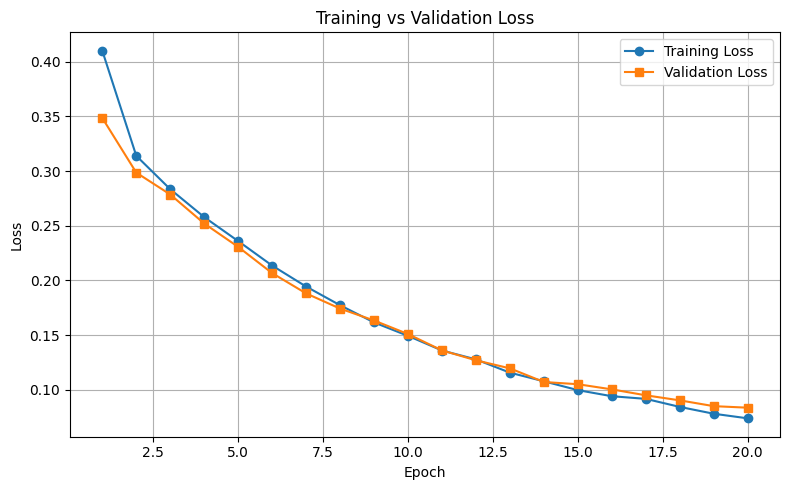

In [33]:
# ==========================================================
# Step 18 : Plot Training and Validation Curves
# ==========================================================

epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    train_loss_history,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    val_loss_history,
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

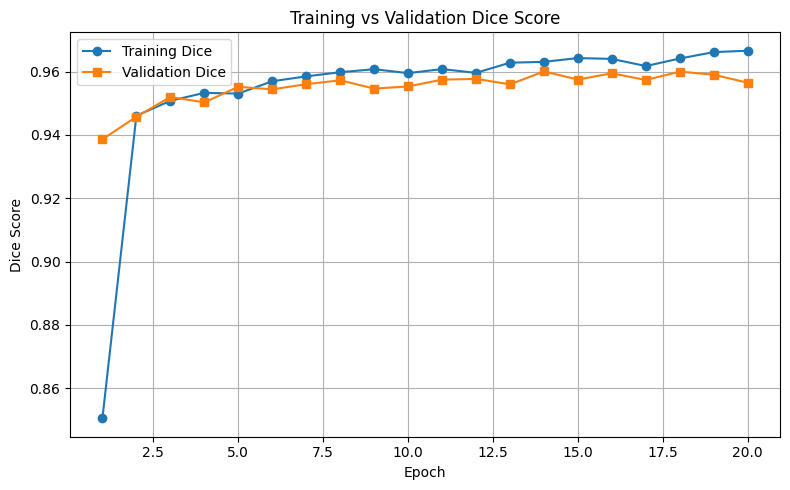

In [34]:
# ==========================================================
# Step 18.1 : Plot Dice Score Curves
# ==========================================================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    train_dice_history,
    marker="o",
    label="Training Dice"
)

plt.plot(
    epochs_range,
    val_dice_history,
    marker="s",
    label="Validation Dice"
)

plt.xlabel("Epoch")
plt.ylabel("Dice Score")
plt.title("Training vs Validation Dice Score")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [35]:
# ==========================================================
# Step 19 : Load Best U-Net Model
# ==========================================================

best_model_path = models_dir / "best_unet.pth"

# Create fresh model
best_model = UNet(
    in_channels=1,
    out_channels=1
).to(device)

# Load checkpoint
checkpoint = torch.load(
    best_model_path,
    map_location=device
)

# Load trained weights
best_model.load_state_dict(
    checkpoint["model_state_dict"]
)

# Evaluation mode
best_model.eval()

print("=" * 60)
print("Best U-Net Model Loaded")
print("=" * 60)

print("Saved Epoch      :", checkpoint["epoch"])
print("Validation Dice  :", f"{checkpoint['val_dice']:.4f}")
print("Validation Loss  :", f"{checkpoint['val_loss']:.4f}")
print("Model Device     :", next(best_model.parameters()).device)

Best U-Net Model Loaded
Saved Epoch      : 14
Validation Dice  : 0.9601
Validation Loss  : 0.1072
Model Device     : mps:0


In [36]:
# ==========================================================
# Step 19.1 : Predict Validation Masks
# ==========================================================

# Get one validation batch
images, masks = next(iter(val_loader))

images = images.to(device)
masks = masks.to(device)

with torch.no_grad():

    logits = best_model(images)

    # Convert logits -> probabilities
    probabilities = torch.sigmoid(logits)

    # Convert probabilities -> binary masks
    predictions = (probabilities >= 0.5).float()

print("=" * 60)
print("Prediction Test")
print("=" * 60)

print("Images       :", images.shape)
print("Ground Truth :", masks.shape)
print("Predictions  :", predictions.shape)

print("\nPrediction Values:")
print(torch.unique(predictions))

Prediction Test
Images       : torch.Size([4, 1, 256, 256])
Ground Truth : torch.Size([4, 1, 256, 256])
Predictions  : torch.Size([4, 1, 256, 256])

Prediction Values:
tensor([0., 1.], device='mps:0')


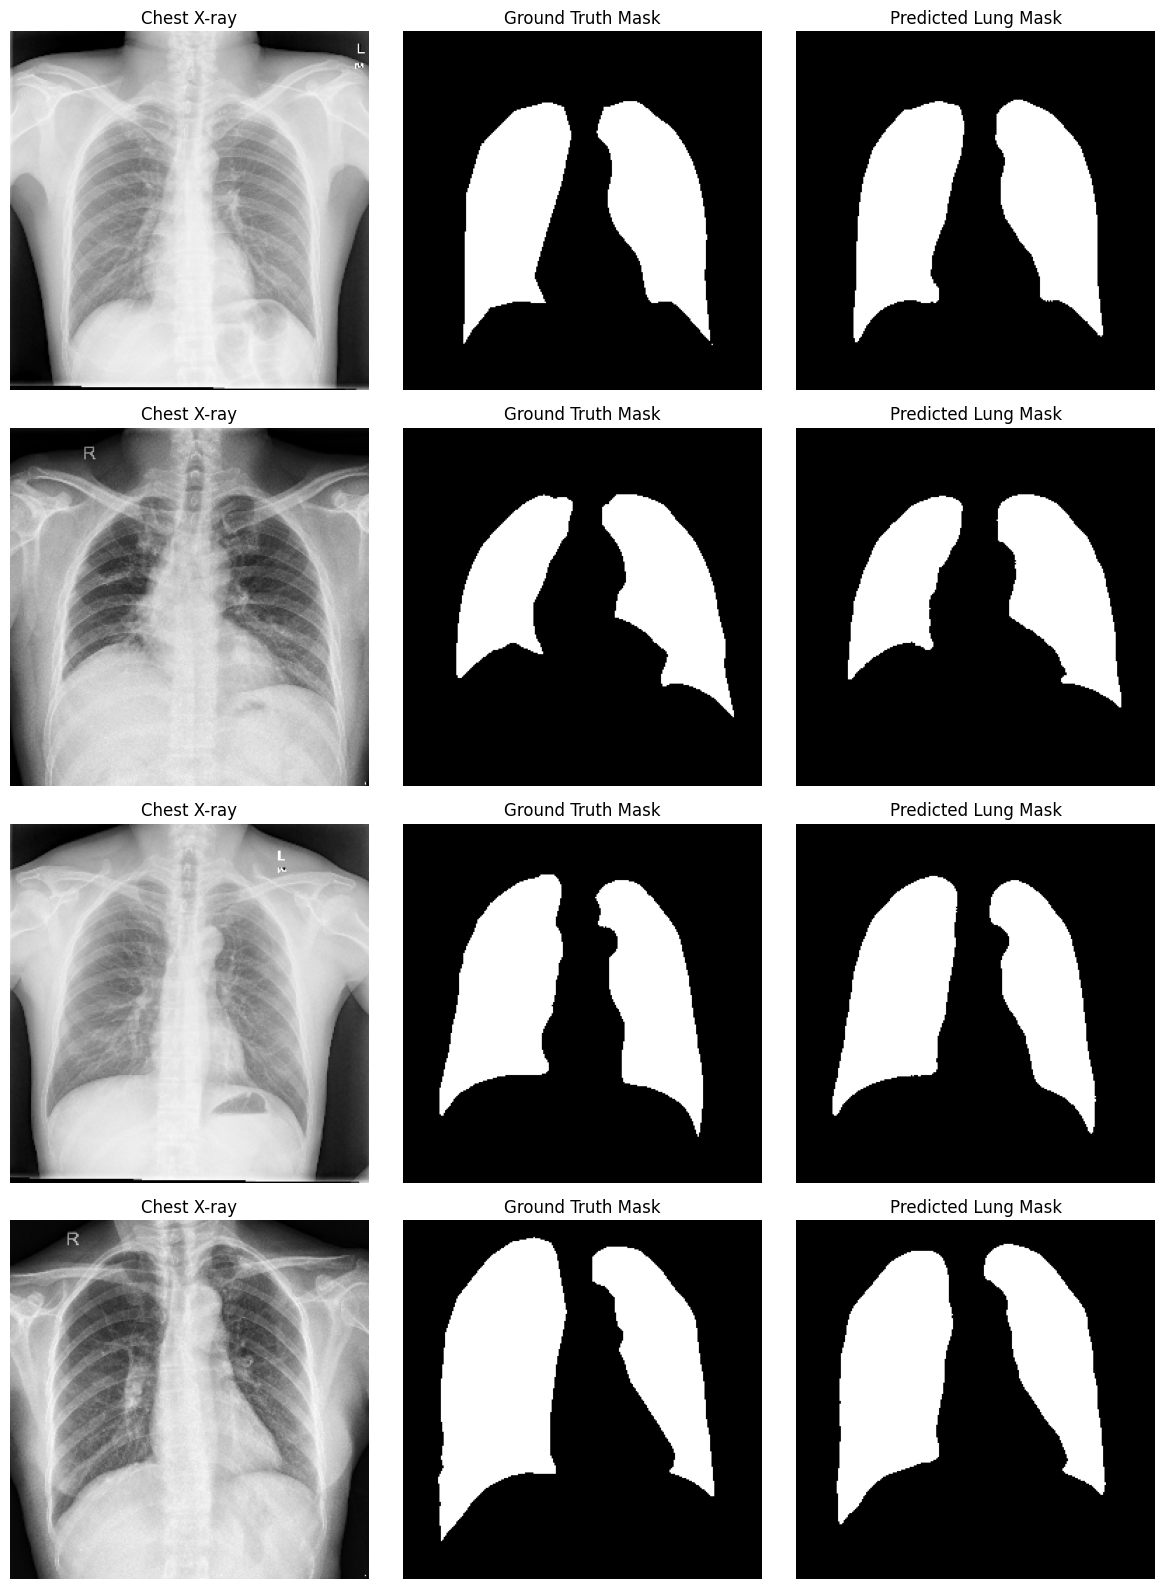

In [37]:
# ==========================================================
# Step 19.2 : Visualize Predicted Lung Masks
# ==========================================================

# Move data back to CPU for matplotlib
images_cpu = images.cpu()
masks_cpu = masks.cpu()
predictions_cpu = predictions.cpu()

num_samples = min(4, len(images_cpu))

plt.figure(figsize=(12, 4 * num_samples))

for i in range(num_samples):

    # -----------------------------
    # Original X-ray
    # -----------------------------
    plt.subplot(num_samples, 3, 3*i + 1)

    plt.imshow(
        images_cpu[i].squeeze(),
        cmap="gray"
    )

    plt.title("Chest X-ray")
    plt.axis("off")

    # -----------------------------
    # Ground Truth
    # -----------------------------
    plt.subplot(num_samples, 3, 3*i + 2)

    plt.imshow(
        masks_cpu[i].squeeze(),
        cmap="gray"
    )

    plt.title("Ground Truth Mask")
    plt.axis("off")

    # -----------------------------
    # Predicted Mask
    # -----------------------------
    plt.subplot(num_samples, 3, 3*i + 3)

    plt.imshow(
        predictions_cpu[i].squeeze(),
        cmap="gray"
    )

    plt.title("Predicted Lung Mask")
    plt.axis("off")

plt.tight_layout()
plt.show()

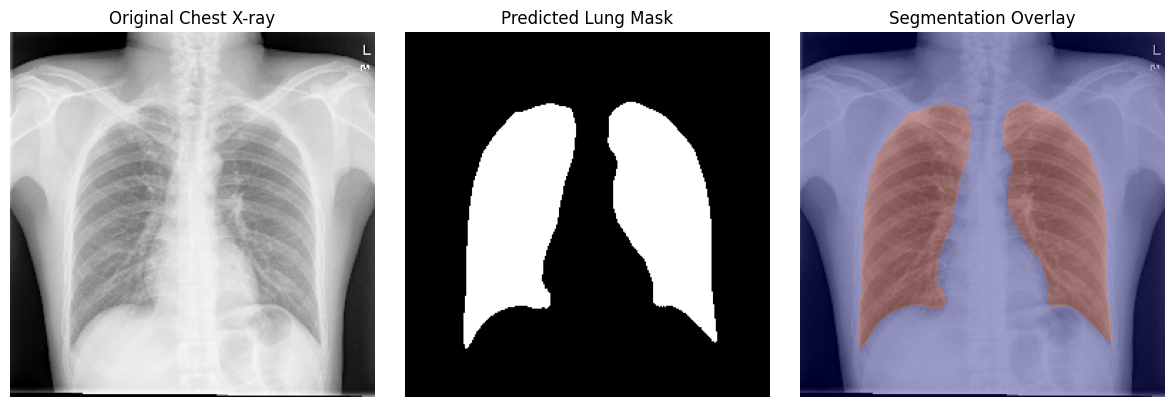

In [38]:
# ==========================================================
# Step 19.3 : Overlay Predicted Mask on Chest X-ray
# ==========================================================

sample_index = 0

image_np = images_cpu[sample_index].squeeze().numpy()
pred_np = predictions_cpu[sample_index].squeeze().numpy()

plt.figure(figsize=(12, 4))

# Original
plt.subplot(1, 3, 1)
plt.imshow(image_np, cmap="gray")
plt.title("Original Chest X-ray")
plt.axis("off")

# Predicted mask
plt.subplot(1, 3, 2)
plt.imshow(pred_np, cmap="gray")
plt.title("Predicted Lung Mask")
plt.axis("off")

# Overlay
plt.subplot(1, 3, 3)

plt.imshow(image_np, cmap="gray")

plt.imshow(
    pred_np,
    alpha=0.35,
    cmap="jet"
)

plt.title("Segmentation Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [39]:
# ==========================================================
# Step 20 : Final Evaluation on Validation Set
# Dice Score + IoU + Validation Loss
# ==========================================================

def calculate_iou(preds, targets, smooth=1e-6):
    """
    Calculate IoU (Jaccard Index) for binary segmentation.
    """

    preds = preds.view(preds.size(0), -1)
    targets = targets.view(targets.size(0), -1)

    intersection = (preds * targets).sum(dim=1)

    union = (
        preds.sum(dim=1)
        + targets.sum(dim=1)
        - intersection
    )

    iou = (
        intersection + smooth
    ) / (
        union + smooth
    )

    return iou.mean().item()


# ----------------------------------------------------------
# Evaluation
# ----------------------------------------------------------

best_model.eval()

total_loss = 0.0
total_dice = 0.0
total_iou = 0.0

num_batches = 0

with torch.no_grad():

    for images, masks in tqdm(
        val_loader,
        desc="Final Validation Evaluation"
    ):

        images = images.to(device)
        masks = masks.to(device)

        # Forward pass
        logits = best_model(images)

        # Validation loss
        loss = criterion(logits, masks)

        # Probabilities
        probs = torch.sigmoid(logits)

        # Binary predictions
        preds = (probs >= 0.5).float()

        # Dice
        batch_dice = dice_score_from_logits(
            logits,
            masks
        )

        # IoU
        batch_iou = calculate_iou(
            preds,
            masks
        )

        total_loss += loss.item()
        total_dice += batch_dice
        total_iou += batch_iou

        num_batches += 1


# ----------------------------------------------------------
# Final averages
# ----------------------------------------------------------

final_val_loss = total_loss / num_batches
final_dice = total_dice / num_batches
final_iou = total_iou / num_batches


print("=" * 70)
print("FINAL LUNG SEGMENTATION RESULTS")
print("=" * 70)

print(f"Validation Samples : {len(val_dataset)}")
print(f"Validation Loss    : {final_val_loss:.4f}")
print(f"Dice Score         : {final_dice:.4f}")
print(f"IoU Score          : {final_iou:.4f}")

print("-" * 70)

print(f"Dice Percentage    : {final_dice * 100:.2f}%")
print(f"IoU Percentage     : {final_iou * 100:.2f}%")

print("=" * 70)

Final Validation Evaluation:   0%|          | 0/29 [00:00<?, ?it/s]

FINAL LUNG SEGMENTATION RESULTS
Validation Samples : 114
Validation Loss    : 0.1072
Dice Score         : 0.9601
IoU Score          : 0.9244
----------------------------------------------------------------------
Dice Percentage    : 96.01%
IoU Percentage     : 92.44%


In [40]:
# ==========================================================
# Step 20.1 : Save Final Segmentation Metrics
# ==========================================================

import pandas as pd

metrics = pd.DataFrame({
    "Metric": [
        "Validation Loss",
        "Dice Score",
        "IoU Score"
    ],

    "Value": [
        final_val_loss,
        final_dice,
        final_iou
    ]
})

metrics_path = outputs_dir / "lung_segmentation_metrics.csv"

metrics.to_csv(
    metrics_path,
    index=False
)

print("Metrics saved successfully:")
print(metrics_path)

metrics

Metrics saved successfully:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/outputs/lung_segmentation_metrics.csv


,Metric,Value
0,Validation Loss,0.107209
1,Dice Score,0.960050
2,IoU Score,0.924410


In [41]:
# ==========================================================
# Step 21.1 : NIH ChestX-ray14 Paths
# ==========================================================

nih_images_dir = project_root / "dataset" / "images"

nih_masks_dir = project_root / "dataset" / "lung_masks"

# Create output folder
nih_masks_dir.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("NIH Lung Mask Generation")
print("=" * 70)

print("NIH Images Folder :", nih_images_dir)
print("Output Mask Folder:", nih_masks_dir)

print("\nFolder Check")
print("NIH Images Exists :", nih_images_dir.exists())
print("Mask Folder Exists:", nih_masks_dir.exists())

NIH Lung Mask Generation
NIH Images Folder : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/dataset/images
Output Mask Folder: /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/dataset/lung_masks

Folder Check
NIH Images Exists : True
Mask Folder Exists: True


In [42]:
# ==========================================================
# Step 21.2 : Find NIH Chest X-ray Images
# ==========================================================

nih_image_files = sorted(nih_images_dir.glob("*.png"))

print("=" * 70)
print("NIH ChestX-ray14 Dataset")
print("=" * 70)

print("Total NIH Images Found :", len(nih_image_files))

if len(nih_image_files) > 0:
    print("\nFirst 5 images:")

    for path in nih_image_files[:5]:
        print(path.name)

NIH ChestX-ray14 Dataset
Total NIH Images Found : 112120

First 5 images:
00000001_000.png
00000001_001.png
00000001_002.png
00000002_000.png
00000003_000.png


In [43]:
# ==========================================================
# Step 21.3 : NIH Inference Dataset
# ==========================================================

class NIHInferenceDataset(Dataset):

    def __init__(self, image_paths, image_size=256):

        self.image_paths = image_paths
        self.image_size = image_size

    def __len__(self):

        return len(self.image_paths)

    def __getitem__(self, idx):

        image_path = self.image_paths[idx]

        # Read grayscale chest X-ray
        image = cv2.imread(
            str(image_path),
            cv2.IMREAD_GRAYSCALE
        )

        if image is None:
            raise RuntimeError(
                f"Unable to read image: {image_path}"
            )

        # Resize exactly as used during U-Net training
        image = cv2.resize(
            image,
            (self.image_size, self.image_size)
        )

        # Normalize to 0–1
        image = image.astype(np.float32) / 255.0

        # Convert to tensor [1, 256, 256]
        image = torch.from_numpy(image).unsqueeze(0)

        return image, image_path.name

In [44]:
# ==========================================================
# Step 21.4 : NIH Inference DataLoader
# ==========================================================

NIH_BATCH_SIZE = 4

nih_dataset = NIHInferenceDataset(
    nih_image_files,
    image_size=IMG_SIZE
)

nih_loader = DataLoader(
    nih_dataset,
    batch_size=NIH_BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("=" * 70)
print("NIH Inference DataLoader")
print("=" * 70)

print("Images  :", len(nih_dataset))
print("Batch   :", NIH_BATCH_SIZE)
print("Batches :", len(nih_loader))

NIH Inference DataLoader
Images  : 112120
Batch   : 4
Batches : 28030


In [45]:
# ==========================================================
# Step 21.5 : Test Segmentation on NIH Images
# ==========================================================

best_model.eval()

test_images, test_names = next(iter(nih_loader))

test_images = test_images.to(device)

with torch.no_grad():

    logits = best_model(test_images)

    probs = torch.sigmoid(logits)

    test_predictions = (
        probs >= 0.5
    ).float()

print("Input Shape      :", test_images.shape)
print("Prediction Shape :", test_predictions.shape)
print("Mask Values      :", torch.unique(test_predictions))

Input Shape      : torch.Size([4, 1, 256, 256])
Prediction Shape : torch.Size([4, 1, 256, 256])
Mask Values      : tensor([0., 1.], device='mps:0')


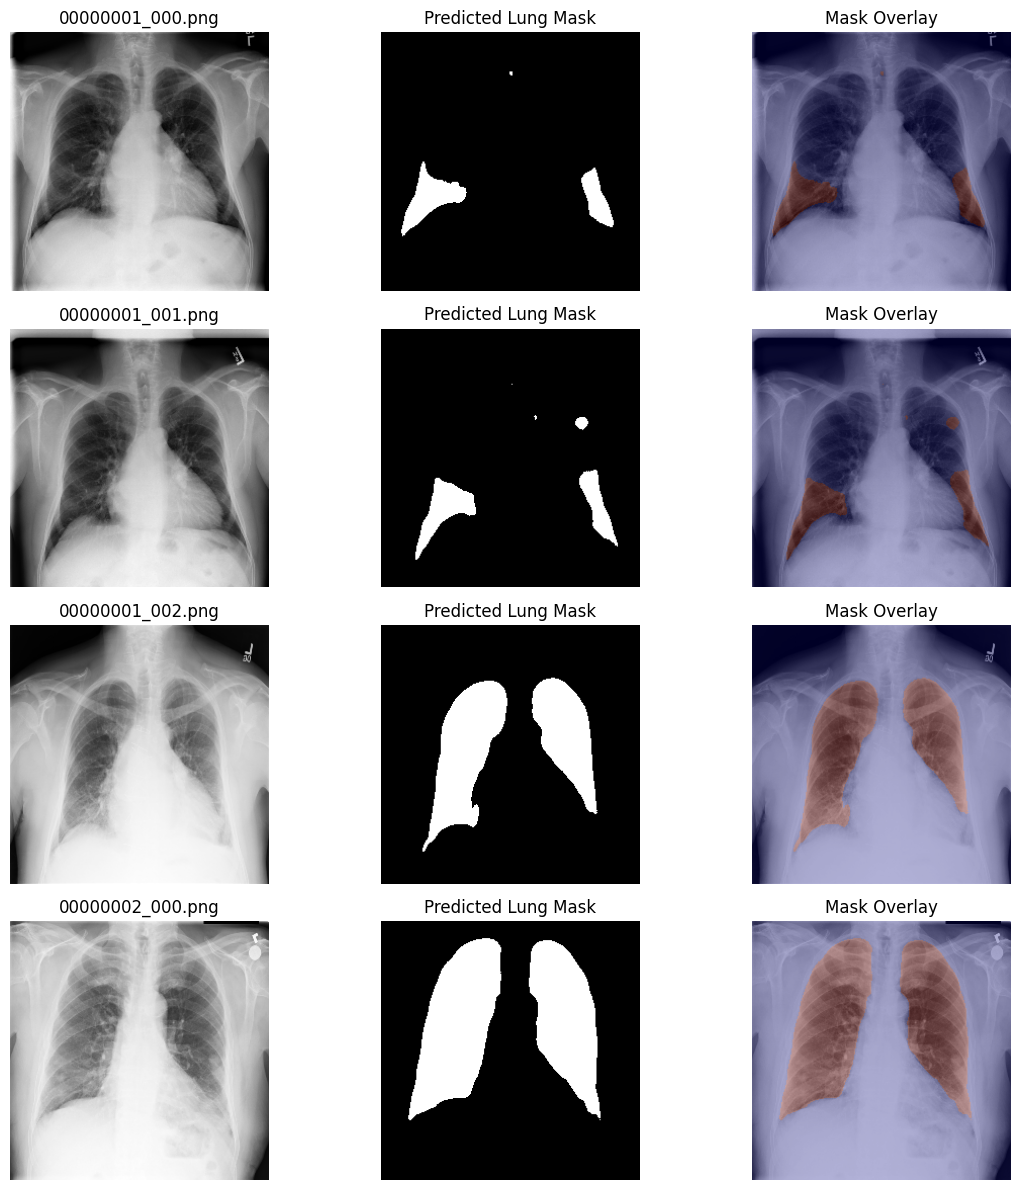

In [46]:
# ==========================================================
# Step 21.6 : Visualize NIH Lung Segmentation
# ==========================================================

test_images_cpu = test_images.cpu()
test_predictions_cpu = test_predictions.cpu()

num_samples = min(4, len(test_images_cpu))

plt.figure(figsize=(12, 3 * num_samples))

for i in range(num_samples):

    image_np = (
        test_images_cpu[i]
        .squeeze()
        .numpy()
    )

    mask_np = (
        test_predictions_cpu[i]
        .squeeze()
        .numpy()
    )

    # Original X-ray
    plt.subplot(num_samples, 3, 3*i + 1)

    plt.imshow(
        image_np,
        cmap="gray"
    )

    plt.title(test_names[i])
    plt.axis("off")

    # Predicted mask
    plt.subplot(num_samples, 3, 3*i + 2)

    plt.imshow(
        mask_np,
        cmap="gray"
    )

    plt.title("Predicted Lung Mask")
    plt.axis("off")

    # Overlay
    plt.subplot(num_samples, 3, 3*i + 3)

    plt.imshow(
        image_np,
        cmap="gray"
    )

    plt.imshow(
        mask_np,
        cmap="jet",
        alpha=0.30
    )

    plt.title("Mask Overlay")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [47]:
# ==========================================================
# Step 21.7 : Generate NIH Lung Masks
# ==========================================================

best_model.eval()

saved_count = 0
skipped_count = 0

with torch.no_grad():

    for images, filenames in tqdm(
        nih_loader,
        desc="Generating NIH Lung Masks"
    ):

        # --------------------------------------------------
        # Check which masks already exist
        # --------------------------------------------------

        existing = [
            (
                nih_masks_dir /
                f"{Path(name).stem}_mask.png"
            ).exists()
            for name in filenames
        ]

        # If entire batch already processed
        if all(existing):
            skipped_count += len(filenames)
            continue

        # --------------------------------------------------
        # Model inference
        # --------------------------------------------------

        images = images.to(device)

        logits = best_model(images)

        probs = torch.sigmoid(logits)

        predictions = (
            probs >= 0.5
        ).float()

        predictions = (
            predictions
            .cpu()
            .numpy()
        )

        # --------------------------------------------------
        # Save each mask
        # --------------------------------------------------

        for prediction, filename, already_exists in zip(
            predictions,
            filenames,
            existing
        ):

            if already_exists:
                skipped_count += 1
                continue

            # [1, 256, 256] -> [256, 256]
            mask = prediction.squeeze()

            # 0/1 -> 0/255
            mask = (
                mask * 255
            ).astype(np.uint8)

            output_name = (
                f"{Path(filename).stem}_mask.png"
            )

            output_path = (
                nih_masks_dir /
                output_name
            )

            cv2.imwrite(
                str(output_path),
                mask
            )

            saved_count += 1

        # Help release Apple MPS memory
        if device.type == "mps":
            torch.mps.empty_cache()


print("\n" + "=" * 70)
print("NIH LUNG MASK GENERATION COMPLETED")
print("=" * 70)

print("New Masks Saved :", saved_count)
print("Existing Skipped:", skipped_count)
print("Output Folder   :", nih_masks_dir)

Generating NIH Lung Masks:   0%|          | 0/28030 [00:00<?, ?it/s]

libpng warning: iCCP: profile 'ICC Profile': 'GRAY': Gray color space not permitted on RGB PNG
libpng warning: iCCP: profile 'ICC Profile': 'GRAY': Gray color space not permitted on RGB PNG



NIH LUNG MASK GENERATION COMPLETED
New Masks Saved : 0
Existing Skipped: 112120
Output Folder   : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/dataset/lung_masks
